In [1]:
import os
import matplotlib.pyplot as plt

from si.io.csv_file import read_csv
from si.model_selection.split import train_test_split
from si.models.linear_regression import RidgeRegression
from si.models.ridge_regression_least_squares import RidgeRegressionLeastSquares

# ajusta o caminho ao teu cpu.csv (o notebook corre a partir da pasta scripts/)
DATASET_PATH = os.path.join("..", "datasets", "cpu", "cpu.csv")
dataset = read_csv(DATASET_PATH, sep=",", features=True, label=True)
dataset.X.shape, dataset.y.shape

((209, 6), (209,))

In [2]:
train, test = train_test_split(dataset, test_size=0.2, random_state=42)
train.X.shape, test.X.shape

((168, 6), (41, 6))

## 3. RidgeRegression (Gradient Descent)

In [ ]:
ridge = RidgeRegression(l2_penalty=1.0, alpha=0.01, max_iter=2000, patience=10, scale=True)
ridge.fit(train)

print("Score (MSE) teste:", ridge.score(test))
print("Custo (teste):    ", ridge.cost(test))
print("Iterações feitas: ", len(ridge.cost_history))

Score (MSE) teste: 5799.783544344606
Custo (teste):     2988.849840710354
Iterações feitas:  2000


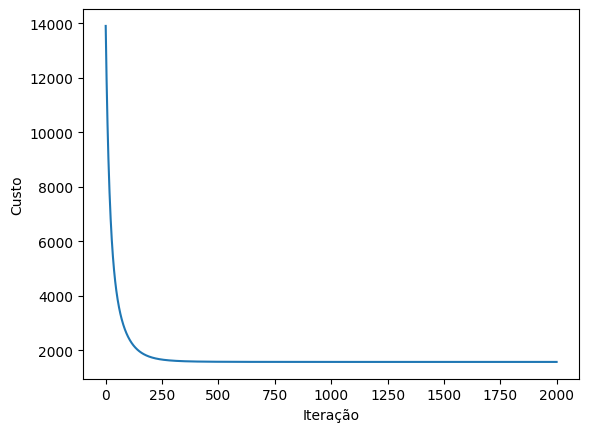

In [4]:
plt.plot(list(ridge.cost_history.keys()), list(ridge.cost_history.values()))
plt.xlabel("Iteração")
plt.ylabel("Custo")
plt.show()

## 4. RidgeRegressionLeastSquares

In [ ]:
ridge_ls = RidgeRegressionLeastSquares(l2_penalty=1.0, scale=True)
ridge_ls.fit(train)

print("Score (MSE) teste:", ridge_ls.score(test))
print("theta_zero:", ridge_ls.theta_zero)
print("theta:", ridge_ls.theta)

Score (MSE) teste: 5806.078466084657
theta_zero: 99.05952380952381
theta: [11.27246675 36.97025942 64.0488686  25.76068496  2.77451415 32.09506132]
